# Lava Blast (Harakim)

Lava Blast replaces Blast once the talent is learned (the `SK_BLAST` investment moves to
`SK_LAVA_BLAST`). The direct hit and the 75% splash are the same as Blast's. Every target the
hit gets through to also starts a 15 s Lava Burn. Unlike Blast, the cast has to win a resist roll
against the primary target first.

| | |
|---|---|
| Class | Harakim |
| Target | Primary target + Blast's AoE splash (75% damage) |
| Cost | $\left(\lfloor\lfloor 3p'/2\rfloor/8\rfloor + 8\right)/3$ mana for player Harakim, spent **before** the roll |
| Cooldown | 6 s exhaust (same as Blast) |
| Landing roll | `chance_base(skill, 12, effective_resist(Resist))` on the primary target; a miss cancels the whole cast, splash included |
| Duration | burn 15 s, one tick per second |
| Damage | direct `do_hurt(2p', 1)`; splash `do_hurt(⌊2p'/2⌋ + ⌊2p'/4⌋, 1)`; burn `max(1, ⌊max(1, ⌊3p'/4⌋)/2⌋)` HP/s, no armor |
| Source | `server/src/driver/skill/harakim.rs::skill_lava_blast`, `apply_lava_blast_dot`; tick in `server/src/state/stats.rs`; Blast in `driver/skill/blast.rs` |

---

# Formula

With $p$ the raw modified skill and $p' = \text{race}(\text{immunity}(p))$:

$$
\text{direct} = \tfrac{3}{4}\max(0,\ 2p' - \text{armor})
\qquad
\text{burn} = \max\!\left(1,\ \left\lfloor \tfrac{\max(1,\ \lfloor 3p'/4 \rfloor)}{2} \right\rfloor\right)\ \text{HP/s}
$$

$$
P(\text{land}) = \frac{\operatorname{clamp}\!\left(\lfloor 12p/R_\text{eff}\rfloor,\ 0,\ 18\right) + 1}{20}
\quad (0 \text{ if } R_\text{eff} > \lfloor 3p/2 \rfloor)
$$

The burn is applied only when the hit removes at least 1 HP, and it uses $p'$ without the
Element Switching bonus (which only multiplies the direct damage, ×1.2). A recast replaces the
running burn, because `add_spell` only keeps the old item when it has more than 60 s left.
Recasting every 6 s therefore realises about 6 of the 15 ticks per cast.

| Quantity | Breakpoint |
|---|---|
| Burn at the raise caps | 39 HP/s at $p'$ 105 (585 HP over 15 s), 45 HP/s at 120 |
| Cost at the raise caps | 9 mana at 105 (Blast: 10), 10 at 120 (Blast: 11) |
| Landing roll | 95% while $R_\text{eff} \le \tfrac{2}{3}p$; 0% above $\tfrac{3}{2}p$ |
| Ceiling | none: direct hit and burn grow linearly |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
EXHAUST_S = 6
BURN_S = 15
ELEMENT_SWITCH_PCT = 20

# Model

In [2]:
def lava_cost(pp):
    return mm.idiv(mm.idiv(np.asarray(pp) * 3, 2) // 8 + 8, 3)


def blast_cost(pp):
    return mm.idiv(np.asarray(pp) * 2 // 8 + 5, 3)


def direct_hp(pp, armor=0, switched=False):
    dam = np.asarray(pp) * 2
    if switched:
        dam = dam * (100 + ELEMENT_SWITCH_PCT) // 100
    return mm.hurt_hp(dam, armor, kind=1)


def splash_hp(pp, armor=0):
    dam = np.asarray(pp) * 2
    return mm.hurt_hp(dam // 2 + dam // 4, armor, kind=1)


def burn_hps(pp):
    return mm.dot_tick(np.maximum(1, pp), "lava")


def p_land(p, resist, pen_pct=0):
    return mm.p_chance_base(p, 12, mm.effective_resist(resist, pen_pct))


def burn_ticks_per_cast(q):
    """Expected burn ticks per 6 s window when recasting on exhaust with landing chance q.

    A landed cast restarts the 15 s burn, so a window gets 6 ticks if this cast or the previous one
    landed, and 3 (ticks 13-15) if only the cast two before landed."""
    q = np.asarray(q, dtype=float)
    return 6 * q + 6 * (1 - q) * q + 3 * (1 - q) ** 2 * q


def lava_dps(p, resist, armor=0, immun=0):
    pp = mm.spell_power(p, immun, "Harakim")
    q = p_land(p, resist)
    hit = direct_hp(pp, armor)
    burn = np.where(hit > 0, burn_hps(pp), 0)
    return (q * hit + burn * burn_ticks_per_cast(q)) / EXHAUST_S


def blast_dps(p, armor=0, immun=0):
    return direct_hp(mm.spell_power(p, immun, "Harakim"), armor) / EXHAUST_S

# Validation

- `lava_blast_dot_records_caster_and_burns_for_15_seconds`: power 0 is stored as 1 and the item
  lasts `TICKS*15`.
- `compute_blast_damage_is_double_power_after_immunity`: skill 50 → (50, 100); with Immunity 40 →
  (30, 60). Lava Blast uses the same direct damage.
- `element_switching_boosts_changed_element_damage`: 100 → 100 on the same element, 120 after a
  switch.

In [3]:
assert burn_hps(0) == 1 and mm.TICKS * BURN_S == 540
assert mm.spell_power(50, 0, "Harakim") == 50 and mm.spell_power(50, 40, "Harakim") == 30
assert 50 * 2 == 100 and 30 * 2 == 60
assert 100 * (100 + ELEMENT_SWITCH_PCT) // 100 == 120
assert burn_hps(105) == 39 and burn_hps(120) == 45
assert lava_cost(105) == 9 and blast_cost(105) == 10 and lava_cost(120) == 10 and blast_cost(120) == 11
assert direct_hp(105) == 157.5 and splash_hp(105) == (105 + 52) * 0.75
assert p_land(105, 70) == 0.95 and p_land(105, 158) == 0.0 and p_land(105, 157) == 0.45
assert burn_ticks_per_cast(1.0) == 6
print("Lava Blast model OK")

Lava Blast model OK


# Plots

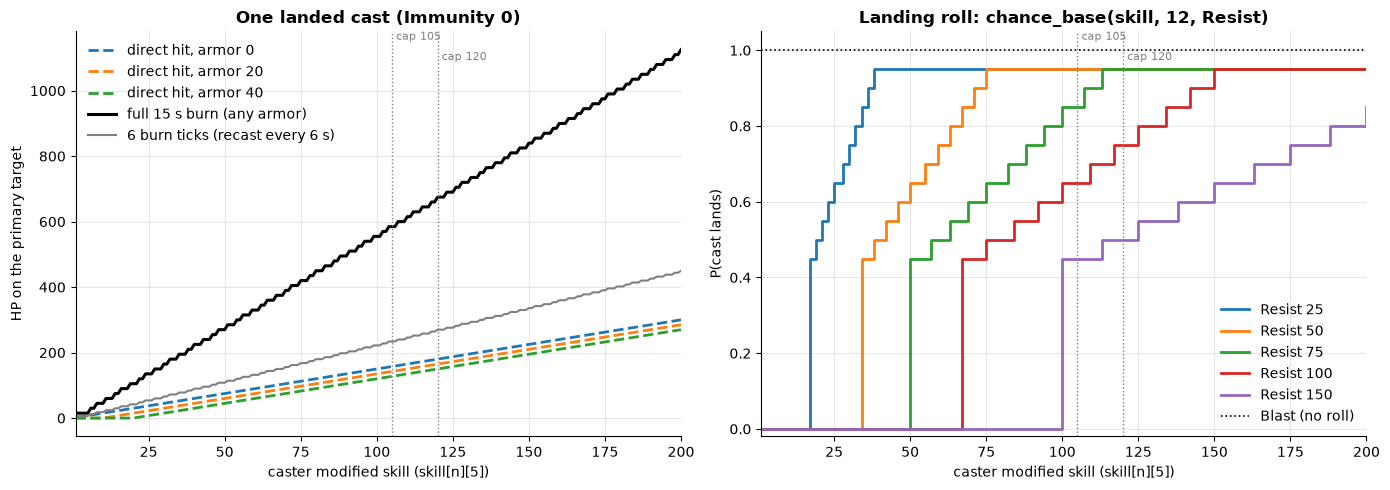

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in (0, 20, 40):
    line, = ax.plot(P, direct_hp(P, armor), ls="--", label=f"direct hit, armor {armor}")
ax.plot(P, BURN_S * burn_hps(P), color="black", lw=2.2, label="full 15 s burn (any armor)")
ax.plot(P, 6 * burn_hps(P), color="grey", lw=1.5, label="6 burn ticks (recast every 6 s)")
mm.skill_axis(ax, "HP on the primary target", "One landed cast (Immunity 0)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for r in mm.RESIST_SWEEP:
    ax.step(P, p_land(P, r), where="post", label=f"Resist {r}")
ax.axhline(1.0, color="black", ls=":", lw=1.2, label="Blast (no roll)")
mm.skill_axis(ax, "P(cast lands)", "Landing roll: chance_base(skill, 12, Resist)")
ax.set_ylim(-0.02, 1.05)
mm.mark_caps(ax)
ax.legend(loc="lower right")
plt.tight_layout()

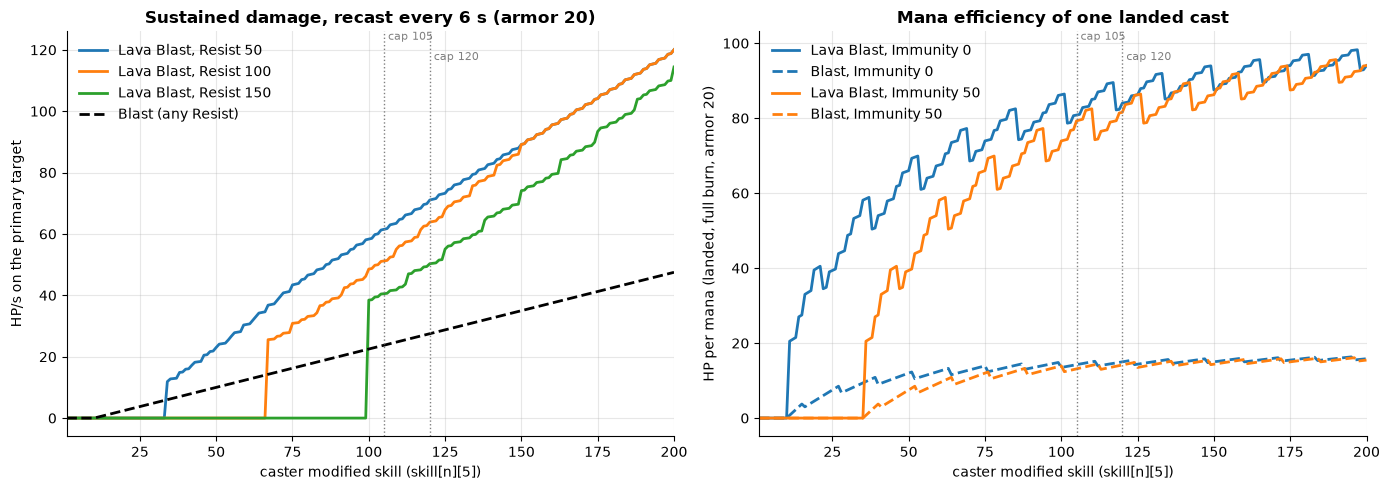

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for r in (50, 100, 150):
    ax.plot(P, lava_dps(P, r, armor=20), label=f"Lava Blast, Resist {r}")
ax.plot(P, blast_dps(P, armor=20), color="black", ls="--", label="Blast (any Resist)")
mm.skill_axis(ax, "HP/s on the primary target", "Sustained damage, recast every 6 s (armor 20)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for imm, color in ((0, "tab:blue"), (50, "tab:orange")):
    pp = mm.spell_power(P, imm, "Harakim")
    hit = direct_hp(pp, 20)
    lava = hit + np.where(hit > 0, BURN_S * burn_hps(pp), 0)
    ax.plot(P, lava / lava_cost(pp), color=color, label=f"Lava Blast, Immunity {imm}")
    ax.plot(P, hit / blast_cost(pp), color=color, ls="--", label=f"Blast, Immunity {imm}")
mm.skill_axis(ax, "HP per mana (landed, full burn, armor 20)", "Mana efficiency of one landed cast")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- **The burn is the real damage.** At $p'$ 105 one landed cast deals 142.5 HP direct (armor 20)
  and then 585 HP of burn that armor cannot reduce. That is about 5× Blast's 142.5 HP for one
  mana less (9 vs 10). Per landed cast that is 81 HP per mana against Blast's 14.
- **The splash burns too.** Every splash target that takes at least 1 HP gets the full 15 s burn.
  At 105 a splash target loses 102.75 + 585 HP, and splash targets never roll: only the primary
  target's Resist gates the whole cast.
- **Sustained, Lava Blast is 2–2.6× Blast even with the roll.** Recast every 6 s, a replaced burn
  realises about 6 ticks per cast (4.6 to 6 depending on how often the cast lands). Against armor
  20 at skill 105 that is 61.5 / 51.2 / 40.5 HP/s against Resist 50 / 100 / 150, against Blast's
  23.8 HP/s. Below Resist ≈ ⅔ of the skill the roll is a flat 95%.
- **The roll is a real step backwards against high Resist.** Blast never misses. Lava Blast does
  nothing at all when $R_\text{eff} > \lfloor 3p/2 \rfloor$ (Resist 158 or more at skill 105),
  and the mana is spent before the roll either way.
- **It removes the Anguish-Lava combo.** `compute_blast_damage` looks for the Anguish-Lava marker,
  but `skill_lava_blast` computes its own damage and never does. Lava Blast replaces Blast, so a
  Harakim who takes both talents can never consume the marker (see `harakim_anguish_lava`).
- **The doc comment on `cast_blast_effect` is stale.** It says the function "rolls the
  resist/sense chance". Blast has no roll; only Lava Blast does.
- **Balance suggestions.** Halve the burn again (`base/4`, about 19 HP/s at 105) or shorten it to
  6 s so it matches the recast interval. Let Lava Blast consume the Anguish-Lava marker, or let
  the marker amplify the burn.